---
## **S30 - Evidencia de Aprendizaje 1. Análisis y herramientas de extracción de datos**
---
**Grupos_PREICA2602B020048**

**Grupo Actividad: 11**

**Materia: Programación para Análisis de Datos**

**Docente: Andrés Felipe Palacio Angel**

**Ingenieria de Software y de Datos**

**6 Semestre**

---


***1. Selecciona una página de comercio electrónico, donde se manejen compras en línea, y aplica los conceptos vistos sobre la metodología empleada de scraping: Beautifulsoup, Selenium y/o Scrapy. Para ello, debes elegir uno de los artículos publicados en la página seleccionada:***

Para el desarrollo de esta actividad 1, tuve algunos problemas a la hora de realizar web scrapping y de elegir una pagina adecuada para web srapping, probé con las solicitadas por la guia ocmo: Amazon, Mercado Libre, y otros ocmo el Exito, entre otras plataformas grandes de comercio, sin embargo tenian muchas restricciones y bloqueos a estas técnicas, como en clase el profesor recomendó y autorizo poder usar “Tiendas Branchos”, seleccione lo siguiente:

  - **Selección de e-commerce: Tiendas Branchos**

  - **Artículo: Categoría Camisetas Mujeres**

  - **Tecnica de Scraping: Beautifulsoup (Web Scraping)**

Ya con el sitio, articulo y tecnica de scrapping elegida, se procede a adaptar e implementar el proceso de extracción automatizada de datos desde el catálogo de la tienda virtual Tiendas Branchos para la categoria de camisetas para muujeres. A continuación se detallan los componentes técnicos y metodológicos utilizados:

* ***Validación Ética (`robots.txt`):*** Antes de adaptar todo el codigo, se verificaron previamente y manualmente las directrices del archivo de exclusión de robots del sitio web: https://www.tiendasbranchos.com/robots.txt , asegurando que la ruta de categorías de ropa analizada no presentara restricciones explícitas de acceso público para bots.

* ***Herramientas y Librerías:*** Python, Requests (para peticiones HTTP), BeautifulSoup (para parseo HTML y búsqueda de scripts), Pandas (para limpieza, estructuración y exportación de datos) y Matplotlib para las visualizaciones.

* ***URL Objetivo:*** `https://www.tiendasbranchos.com/mujeres/ropa/camisetas?page={pagina}` (recorriendo la paginación de forma controlada y con respeto).
* ***Método y Petición Usada:*** Luego de la validacion manual y fijar la URL, se emplea la librería `BeautifulSoup` en conjunto con peticiones HTTP (`requests.get`) para la extracción de lso atrbutos en los metadatos estructurados oficiales en formato *JSON-LD (Schema.org)* incrustados por la plataforma.
* ***Extracción de Atributos e Identificadores (MPN y SKU):*** A través del análisis del nodo `ItemList` del JSON-LD, se extrajeron de forma estandarizada los metadatos clave de cada producto, destacando la`Referencia Comercial (MPN - Manufacturer Part Number)` y el `código interno SKU`, ademas `Nombre del Producto`, `Marca`, `Categoría`, `Página de origen`, y el `Precio (COP)` garantizando una identificación unívoca sin depender de selectores HTML visuales frágiles.

* ***Estructura Final del Dataset:*** El dataset crudo se exprota en un archivo .CSV con la estructura: `Nombre del Producto`, `Marca`, `Ref Comercial (MPN)`, `Cod Interno (SKU)`, `Categoría`, `Página de origen`, y el `Precio (COP)` posicionado estrictamente en la última columna para facilitar su análisis.

* ***Manejo de Excepciones y Control de Errores*** Para asegurar la resiliencia y el control defensivo en la extracción,se implementa:
  * `requests.exceptions.RequestException` y `Exception`: Intercepta de forma aislada caídas de enlace, timeouts o fallas de DNS.
  * `response.status_code` (Inspección de Códigos de Estado HTTP): Condiciona el flujo según la respuesta del servidor, códigos 200 (OK) y códigos de error o denegación (como 403, 404 o 500).
  * `json.JSONDecodeError` (Integridad de Metadatos Estructurados): Aisla y omite de forma segura bloques Schema.org con sintaxis JSON corrupta o incompleta.


**Nota: Buenas Prácticas Aplicadas (Scraping Idóneo y Ético).**
El script implementado adaptado contiene buenas practicas estandar y de etica del web scraping de la siguiente forma:
  - **Validación Ética:** se verificaron previamente y manualmente las directrices del archivo de exclusión de `robots.txt` del sitio web
  - **Transparencia:** Inclusión de un encabezado `User-Agent` que identifica claramente las solicitudes como un script de investigación.
  - **Cortesía con el Servidor (*Rate Limiting*):** Implementación de una pausa controlada de `3.0 segundos en time.sleep`, entre cada solicitud de página para evitar saturar o degradar el rendimiento del servidor de la tienda.
  - **Minimización de Datos:** Recopilación exclusiva de información pública abierta al consumidor (`nombres, marcas, referencias MPN, SKU y precios`), asegurando la integridad del pipeline ETL antes de su exportación y análisis.

In [ ]:
# WEB SCRAPING Y ANALÍTICA
# Tecnica de Scraping: Beautifulsoup
# Selección de e-commerce: TIENDAS BRANCHOS
# Artículo: Categoría Camisetas Mujeres
# Categoría: Camisetas Mujeres

import pandas as pd  # Libreria principal para análisis de datos mediante DataFrames
import requests  # Ejecución de solicitudes HTTP GET y control de errores
from bs4 import BeautifulSoup  # Parseo HTML y extracción de bloques JSON-LD
import json  # Deserialización de datos estructurados.
import time  # Gestión de pausas (Rate Limiting)

# LISTA ACUMULADORA DE LAS PAGINAS. almacena diccionarios extraídos
productos_camisetas_mujeres = []
paginas_a_descargar = 4 # Pagians de la categoria camisetas mujeres
# Encabezado HTTP User-Agent para identificación y transparencia ética
headers = {
    'User-Agent': (
        'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML,'
        ' like Gecko) Chrome/120.0.0.0 Safari/537.36')}

# EXTRACCION TIENDAS BRANCHOS
print('=== INICIANDO EXTRACCIÓN ÉTICA CON PAGINACION ===')
# Bucle controlado para recorrer la paginación parametrizada del e-commerce
for pagina in range(1, paginas_a_descargar + 1):
  # Url del sitio y agregacion de la pagina dinamica
  url_dinamica = (
      f'https://www.tiendasbranchos.com/mujeres/ropa/camisetas?page={pagina}')
  print(f'> Extrayendo productos de pagina {pagina} de {paginas_a_descargar}:', end='')
  try:
    # Solicitud HTTP GET con control de tiempo de espera (timeout)
    response = requests.get(url_dinamica, headers=headers, timeout=10)

    # Control de Errores HTTP:
    if response.status_code == 200:
      pass  # Petición exitosa, continúa el flujo normal
    elif response.status_code == 404:
      print('Página no encontrada (404). Posible fin de catálogo alcanzado.')
      break
    elif response.status_code == 403:
      print('Acceso prohibido (403). Restricción de seguridad en' ' servidor.')
      break
    elif response.status_code >= 500:
      print('Error interno del servidor remoto (Código:'
          f' {response.status_code}).')
      break
    else:
      print('Respuesta HTTP inesperada (Código: '
          f'{response.status_code}). Deteniendo.')
      break

    # Parseo de la estructura HTML con BeautifulSoup
    soup_pag = BeautifulSoup(response.content, 'html.parser')
    # Extracción de metadatos estructurados oficiales (JSON-LD)
    scripts_json_ld = soup_pag.find_all('script', type='application/ld+json')
    conteo_pagina = 0
    for script in scripts_json_ld:
      try:
        if not script.string:
          continue

        # Deserialización del bloque JSON
        atributos_schema = json.loads(script.string)
        # Validación Esquema ItemList para los productos
        if atributos_schema.get('@type') == 'ItemList' and 'itemListElement' in atributos_schema:
          for item_wrapper in atributos_schema['itemListElement']:
            producto = item_wrapper.get('item', {})
            if producto: # Extracción de atributos comerciales y valores
              nombre = producto.get('name', 'No disponible')
              marca = producto.get('brand', {}).get('name', 'Branchos')
              ref_comercial_mpn = producto.get('mpn', 'No disponible')
              cod_interno_sku = producto.get('sku', 'No disponible')
              # Extracción del precio monetario (COP)
              ofertas = producto.get('offers', {})
              precio = 'No disponible'
              if isinstance(ofertas, dict):
                precio_num = (
                    ofertas.get('highPrice')
                    or ofertas.get('lowPrice')
                    or ofertas.get('price'))
                if precio_num:
                  precio = f'${float(precio_num):,.2f}'

              # Consolidación estructurada del producto en la lista
              productos_camisetas_mujeres.append({
                  'Nombre del Producto': nombre,
                  'Marca': marca,
                  'Ref Comercial (MPN)': ref_comercial_mpn,
                  'Precio (COP)': precio,
                  'Cod Interno (SKU)': cod_interno_sku,
                  'Categoría': 'Camisetas Mujeres',
                  'Página': f'Pág {pagina}',})
              conteo_pagina += 1
      # Forma segura para bloques con sintaxis JSON corrupta o claves faltantes
      except (json.JSONDecodeError, KeyError):
        continue

    print(f'\n ¡Extraccion Éxitosa! {conteo_pagina} productos capturados.')

    # (Rate Limiting): Respeto por los recursos y ancho de banda del servidor
    time.sleep(3.0) # PAUSA 3 SEGUNDOS POR ÉTICA

 # CONTROL DE EXCEPCIONES GENERALES (Capa de Red)
  except requests.exceptions.RequestException as e:
    print(f'Error de red en la página {pagina}: {str(e)}')
  except Exception as e:
    print(f'Error inesperado en la página {pagina}: {str(e)}')

# DATAFRAME INCIAL CRUDO
# Consolidación del DataFrame Crudo inicial
df_camisetas_mujeres = pd.DataFrame(productos_camisetas_mujeres)

if not df_camisetas_mujeres.empty:
    print('\nEXTRACCIÓN FINALIZADA: Total de registros crudos capturados:'
        f' {len(df_camisetas_mujeres)}')
    
    # Vista previa del dataset crudo
    print('\n-------- VISTA PREVIA DEL DATASET CRUDO (HEAD 5) --------')
    display(df_camisetas_mujeres.head(5))
    
    # Exportación automatizada del dataset crudo a CSV localmente en la carpeta del proyecto
    archivo_raw = 'ea1_camisetas_mujeres_dataset_crudo.csv'
    df_camisetas_mujeres.to_csv(
        archivo_raw, index=False, encoding='utf-8-sig', sep=';'
    )
    
    print(f"\nArchivo del dataset con los datos crudos '{archivo_raw}' exportado correctamente en el directorio del proyecto.")
else:
    print('\nError. No se localizan productos.')

=== INICIANDO EXTRACCIÓN ÉTICA CON PAGINACION ===
> Extrayendo productos de pagina 1 de 4:
 ¡Extraccion Éxitosa! 12 productos capturados.
> Extrayendo productos de pagina 2 de 4:
 ¡Extraccion Éxitosa! 12 productos capturados.
> Extrayendo productos de pagina 3 de 4:
 ¡Extraccion Éxitosa! 12 productos capturados.
> Extrayendo productos de pagina 4 de 4:
 ¡Extraccion Éxitosa! 5 productos capturados.

EXTRACCIÓN FINALIZADA: Total de registros crudos capturados: 41

-------- VISTA PREVIA DEL DATASET CRUDO (HEAD 5) --------


,Nombre del Producto,Marca,Ref Comercial (MPN),Precio (COP),Cod Interno (SKU),Categoría,Página
0,Nike Camiseta Nsw Club Ss Tee Icn Mujer Verde,NIKE,67274-XS,"$103,200.00",161720,Camisetas Mujeres,Pág 1
1,Fila Camiseta Selene Mujer Blanco,FILA,67004-XL,"$89,000.00",162937,Camisetas Mujeres,Pág 1
2,Fila Camiseta Selene Mujer Negro,FILA,67003-XL,"$89,000.00",162985,Camisetas Mujeres,Pág 1
3,Fila Camiseta Fabiola Mujer Vinotinto,FILA,67064-XL,"$89,000.00",163486,Camisetas Mujeres,Pág 1
4,Fila Camiseta Gemma Mujer Negro,FILA,67033-XL,"$89,000.00",163501,Camisetas Mujeres,Pág 1



Archivo del dataset con los datos crudos 'camisetas_mujeres_dataset_crudo.csv' exportado correctamente en el directorio del proyecto.


### **ETL, Limpieza y Auditoría de Datos**.
Con los datos ya extraídos y consolidados en le dataset crudo se procede a la carga del dataset en una copia de análisis (`df_camisetas_analisis`). En esta sección se validan los tipos de datos correctos, se realiza un conteo de registros nulos y duplicados por variable, y se calculan las métricas estadísticas básicas (promedio, mínimo, máximo y desviación) para la variable de precios, es decir se procesa y transforma el dataset crudo obtenido del scraping anterior a un nuevo datset limpio con los siguientes componentes clave:

  * **Carga y Verificación de Integridad (Capa de Ingesta ETL):** En esta parte se hace la validación de la existencia del dataset crudo en memoria que hicimos en el scraping; en caso de no encontrarse, se carga de forma segura desde el archivo de respaldo CSV en disco (`ea1_camisetas_mujeres_dataset_crudo.csv`).
   * **Inspección y Filtrado Visual de Registros Duplicados:** Utilizando `Nombre del Producto` como llave de unicidad comercial. se aplica método `.drop_duplicates()` para eliminar repeticiones y conservar catálogo limpio, único y sin redundancias.
  * **Transformación y Limpieza ETL:** Se realzia la limpieza de Moneda con el procesamiento de la cadena de texto de precios para remover símbolos de moneda (`$`), separadores de miles (`,`) y sufijos decimales (`.00`), convirtiéndolo a un tipo de dato numérico (`float64`) en una nueva columna `Precio_Numerico`.
   * **Homogeneización Textual:** Se hace la conversión estricta de todas las columnas de texto (`Nombre del Producto`, `Marca`, `Ref Comercial (MPN)`, `Cod Interno (SKU)`, `Categoría` y `Página`) a tipo cadena (*string*) para garantizar consistencia estructural.

  * **Análisis Estadístico:** Finalmente despues del proceso ETL se genera una tabla resumen con el conteo de registros no nulos y nulos por atributo, tambien se cálcula el *Índice de Completitud de Datos* sobre columnas (`Nombre del Producto`, `Precio_Numerico` y `Marca`), luego de ellos se procede a la ejecución de análisis estadístico descriptivo (`describe()`) sobre los precios y conteo de distribución automatizado por marcas.

  * **Carga y Exportación Final (Capa de Salida ETL):** Por ultimo se exporta el dataset analítico final limpio y ocnsolidado automaticamente a un archivo `.csv` con codificación estándar `utf-8-sig` activando la descarga directa a pc local.

In [3]:
# CARGA, ETL y ANALISIS DEL DATASET CON LOS DATOS EXTRAIDOS
# Verificación de integridad: carga desde memoria o respaldo CSV en disco
print('=== PROCESAMIENTO ETL Y VALIDACIONES ===\n')
try:
  df_etl = df_camisetas_mujeres.copy()
  print('Dataset Inicial: df_camisetas_mujeres, cargado Correctamente desde el archivo CSV crudo previo\n')
except NameError:
  print('Cargando el dataset desde el archivo CSV crudo previo...')
  df_etl = pd.read_csv('camisetas_mujeres_dataset_crudo.csv', sep=';')

# ETL - CONVERSIÓN Y LIMPIEZA DE MONEDA (Transformación a float64)
# Limpieza de caracteres especiales (símbolos monetarios y separadores de miles)
df_etl['Precio_Numerico'] = (
    df_etl['Precio (COP)']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.replace('.00', '', regex=False)
    .astype(float))

# Homogeneización estricta de tipos de datos textuales
columnas_texto = ['Nombre del Producto','Marca','Ref Comercial (MPN)',
    'Cod Interno (SKU)','Categoría','Página',]
for col in columnas_texto:
  if col in df_etl.columns:
    df_etl[col] = df_etl[col].astype(str)

# CONTROL DE DUPLICADOS (Garantía de unicidad comercial)
# Visualización previa de los registros que están duplicados por Nombre del Producto
registros_duplicados = df_etl[df_etl.duplicated(subset=['Nombre del Producto'], keep=False)]
print(f"INSPECCIÓN DE DUPLICADOS (Total encontrados: {len(registros_duplicados)})")
if len(registros_duplicados) > 0:
    display(registros_duplicados)
else:
    print("No se encontraron registros duplicados.")
total_duplicados_previos = df_etl.duplicated(subset=['Nombre del Producto']).sum()

# Consolidación del DataFrame analítico final limpio
df_camisetas_analisis = df_etl.drop_duplicates(
    subset=['Nombre del Producto']).reset_index(drop=True)
print(f'\nControl de Duplicados: Se eliminaron {total_duplicados_previos}'
    ' registros duplicados.')
print(f"Duplicados restantes: {df_camisetas_analisis.duplicated(subset=['Nombre del Producto']).sum()}")
print(f'Total de registros únicos limpios: {len(df_camisetas_analisis)}\n')

# TABLA DE CALIDAD: CARACTERÍSTICAS, TIPOS Y VALORES NULOS
print('========= TABLA RESUMEN DE CARACTERÍSTICAS, TIPOS Y VALORES NULOS =========')
resumen_variables = pd.DataFrame({
    'Columna': df_camisetas_analisis.columns,
    'Tipo de Dato': df_camisetas_analisis.dtypes.values,
    'Registros No Nulos': df_camisetas_analisis.notnull().sum().values,
    'Registros Nulos': df_camisetas_analisis.isnull().sum().values,})
display(resumen_variables)

# ANÁLISIS ESTADÍSTICO DESCRIPTIVO (Métricas clave del negocio)
print('\n=== ANÁLISIS DESCRIPTIVO: PRECIO DE CAMISETAS (COP) ===')
desc_precio = df_camisetas_analisis['Precio_Numerico'].describe()
metricas_clave = desc_precio[['count', 'mean', 'std', 'min', '50%', 'max']]
print(metricas_clave.to_string())
# Conteo automatizado de distribución por marcas
print('\n=== CONTEO DE PRODUCTOS POR MARCA ===')
conteo_marcas = df_camisetas_analisis['Marca'].value_counts()
print(conteo_marcas.to_string())

=== PROCESAMIENTO ETL Y VALIDACIONES ===

Dataset Inicial: df_camisetas_mujeres, cargado Correctamente desde el archivo CSV crudo previo

INSPECCIÓN DE DUPLICADOS (Total encontrados: 2)


,Nombre del Producto,Marca,Ref Comercial (MPN),Precio (COP),Cod Interno (SKU),Categoría,Página,Precio_Numerico
7,Fila Camiseta Octavia Mujer Blanco,FILA,67039-XL,"$109,000.00",163509,Camisetas Mujeres,Pág 1,109000.0
28,Fila Camiseta Octavia Mujer Blanco,FILA,67038-XL,"$109,000.00",163505,Camisetas Mujeres,Pág 3,109000.0



Control de Duplicados: Se eliminaron 1 registros duplicados.
Duplicados restantes: 0
Total de registros únicos limpios: 40

========= TABLA RESUMEN DE CARACTERÍSTICAS, TIPOS Y VALORES NULOS =========


,Columna,Tipo de Dato,Registros No Nulos,Registros Nulos
0,Nombre del Producto,str,40,0
1,Marca,str,40,0
2,Ref Comercial (MPN),str,40,0
3,Precio (COP),str,40,0
4,Cod Interno (SKU),str,40,0
5,Categoría,str,40,0
6,Página,str,40,0
7,Precio_Numerico,float64,40,0



=== ANÁLISIS DESCRIPTIVO: PRECIO DE CAMISETAS (COP) ===
count        40.000000
mean     111265.000000
std       63596.103533
min       50000.000000
50%       96100.000000
max      379000.000000

=== CONTEO DE PRODUCTOS POR MARCA ===
Marca
FILA      23
NIKE      10
ADIDAS     7


In [4]:
# AUDITORÍA DEL DATASET: Estado Final
print('' + '=' * 50)
print('          AUDITORÍA DEL DATASET: Estado Final del Proceso      ')
print('=' * 50)
total_registros = len(df_camisetas_analisis)
columnas_criticas = ['Nombre del Producto', 'Precio_Numerico', 'Marca']
nulos_criticos = df_camisetas_analisis[columnas_criticas].isnull().sum().sum()
completitud = (
    (1 - (nulos_criticos / (total_registros * len(columnas_criticas)))) * 100)

print(f'• Estado General:         EXITOSO')
print(f'• Integridad Estructural:               100% Sin Errores de Tipado')
print(f'• Índice de Completitud de Datos:      {completitud:.1f}%')
print(f'• Registros Huérfanos o Nulos Críticos:  {nulos_criticos}')
print(f'• Duplicados Post-Procesamiento:        0')
print('=' * 50 + '\n')

# Vista previa del dataset analítico limpio y listo
print('--- VISTA PREVIA DEL DATASET ANALÍTICO LIMPIO (HEAD 5) ---')
display(df_camisetas_analisis.head(5))

# =====================================================================
# EXPORTACIÓN FINAL DEL DATASET ANALITICO LISTO PARA BI/EXCEL/HTML
# =====================================================================
# Buenas prácticas de ingeniería de datos (Snake Case y nombre estáticos):
# Se utiliza nombre fijo ('ea1_camisetas_mujeres_analytics.csv')
# fundamental para pipelines automatizados en GitHub Actions,
# evitando saturar el repositorio con múltiples archivos y asegurando que las 
# herramientas de BI o reportes conectados nunca pierdan la ruta de actualización.
# =====================================================================

nombre_archivo_final = 'ea1_camisetas_mujeres_analytics.csv'
df_camisetas_analisis.to_csv(
    nombre_archivo_final, index=False, encoding='utf-8-sig', sep=';')
print(f"\nDataset analítico final exportado y descargado con éxito bajo el nombre:"
    f" '{nombre_archivo_final}'")

          AUDITORÍA DEL DATASET: Estado Final del Proceso      
• Estado General:         EXITOSO
• Integridad Estructural:               100% Sin Errores de Tipado
• Índice de Completitud de Datos:      100.0%
• Registros Huérfanos o Nulos Críticos:  0
• Duplicados Post-Procesamiento:        0

--- VISTA PREVIA DEL DATASET ANALÍTICO LIMPIO (HEAD 5) ---


,Nombre del Producto,Marca,Ref Comercial (MPN),Precio (COP),Cod Interno (SKU),Categoría,Página,Precio_Numerico
0,Nike Camiseta Nsw Club Ss Tee Icn Mujer Verde,NIKE,67274-XS,"$103,200.00",161720,Camisetas Mujeres,Pág 1,103200.0
1,Fila Camiseta Selene Mujer Blanco,FILA,67004-XL,"$89,000.00",162937,Camisetas Mujeres,Pág 1,89000.0
2,Fila Camiseta Selene Mujer Negro,FILA,67003-XL,"$89,000.00",162985,Camisetas Mujeres,Pág 1,89000.0
3,Fila Camiseta Fabiola Mujer Vinotinto,FILA,67064-XL,"$89,000.00",163486,Camisetas Mujeres,Pág 1,89000.0
4,Fila Camiseta Gemma Mujer Negro,FILA,67033-XL,"$89,000.00",163501,Camisetas Mujeres,Pág 1,89000.0



Dataset analítico final exportado y descargado con éxito bajo el nombre: 'ea1_camisetas_mujeres_analytics.csv'



### **Visualización Gráfica de Los Datos de Negocio**

Ya para esta parte final, decidi usar la librería Matplotlib, para representar visualmente los datos extraídos, limpios y cargados del dataset final resultante y generar 2 gráficos estadísticos (Lineas y Barras) limpios y orientados al reporte académico: también una descripción de los principales hallazgos estadísticos del catálogo depurado de **camisetas mujeres**:

* **Hallazgos estadísticos y de mercado** según los resultados se encuentra que el volumen del catálogo: aprox de 40 productos únicos analizados tras el proceso de etl:

  * ***Comportamientos de Precios (COP):*** `Precio mínimo: 50.000`, `Precio máximo: 379.000`, `Precio promedio:111.265` (con una `desviación estándar de $ 63.596`)

  * ***Distribución por Marcas:*** `fila: 23 productos` (mayor presencia en el catálogo), `nike: 10 productos` y `adidas:7 productos`.


* **Descripción de las Gráficas**

  * ***Gráfica 1 - Lineas (Comportamiento de Precios por Referencia - MPN):*** Esta gráfica trae el precio individual de cada producto frente a su referencia comercial mpn única mediante una línea de tendencia, incorporando una línea horizontal continua que representa el precio promedio, para facilitar la identificación rápida de valores por encima o por debajo de la media. Asimismo, incluye llamadas de atención automatizadas con coordenadas dinámicas para señalar el precio mínimo y el máximo. Con los datos obtenidos podemos destacar precio promedio de 111.265, precio mínimo de 50,000 y un máximo de 379,000.

  * ***Gráfica 2 - Barras verticales (Distribución Categórica por Marca):*** Este diagrama de barras verticales representa el volumen de productos disponibles por cada marca, Con los datos obtenidos podemos destacar una oferta liderada por FILA con 23 artículos, seguida por NIKE con 10 y ADIDAS con 7, con un tono único a cada barra para mejorar la visualizacion.

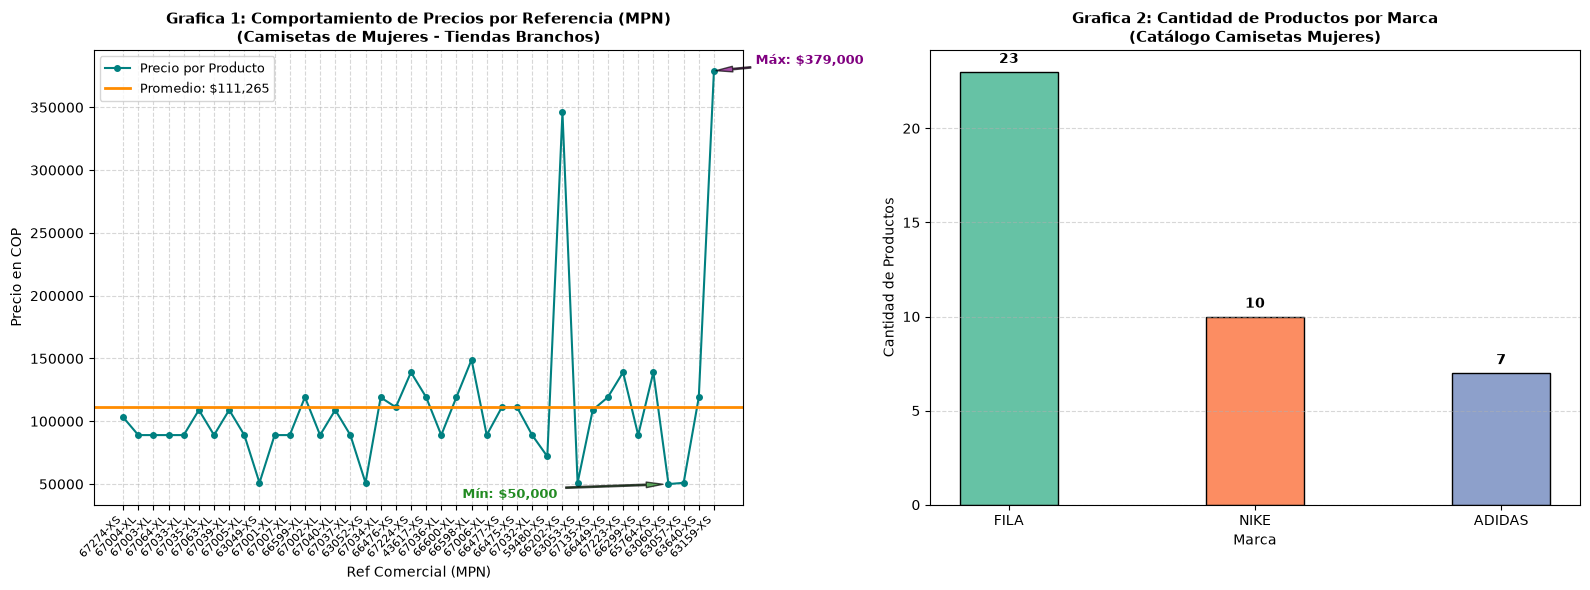

In [6]:
# VISUALIZACION DE LOS DATOS
import matplotlib.pyplot as plt # Importamos Matplotlib para las graficas
fig, axes = plt.subplots(1, 2, figsize=(16, 6)) # Generación de Gráficas

# GRÁFICA 1: Líneas de Precios con Referencia (MPN)
p_min = df_camisetas_analisis['Precio_Numerico'].min()
p_max = df_camisetas_analisis['Precio_Numerico'].max()
p_mean = df_camisetas_analisis['Precio_Numerico'].mean()
# Línea principal de precios
axes[0].plot(df_camisetas_analisis['Ref Comercial (MPN)'],
    df_camisetas_analisis['Precio_Numerico'],
    color='teal',linewidth=1.5,marker='o',markersize=4,
    label='Precio por Producto',)
# Línea horizontal exclusiva para el Promedio
axes[0].axhline(p_mean,color='darkorange',linestyle='-',
    linewidth=2,label=f'Promedio: ${p_mean:,.0f}',)
axes[0].set_title(
    'Grafica 1: Comportamiento de Precios por Referencia (MPN)\n(Camisetas de Mujeres -'
    ' Tiendas Branchos)',fontsize=11,fontweight='bold',)
axes[0].set_xlabel('Ref Comercial (MPN)', fontsize=10)
axes[0].set_ylabel('Precio en COP', fontsize=10)
axes[0].legend(loc='upper left', fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.5)
plt.sca(axes[0]) # Rotar las etiquetas de las referencias en el eje X
plt.xticks(rotation=45, ha='right', fontsize=8)
# Identificar coordenadas de los puntos mínimo y máximo
idx_min = df_camisetas_analisis['Precio_Numerico'].idxmin()
idx_max = df_camisetas_analisis['Precio_Numerico'].idxmax()
ref_min = df_camisetas_analisis.loc[idx_min, 'Ref Comercial (MPN)']
ref_max = df_camisetas_analisis.loc[idx_max, 'Ref Comercial (MPN)']
# Anotación del Mínimo
axes[0].annotate(f'Mín: ${p_min:,.0f}',xy=(ref_min, p_min),xytext=(-80, -10),
    textcoords='offset points',ha='right',fontsize=9,color='forestgreen',
    fontweight='bold',arrowprops=dict(
        facecolor='forestgreen', shrink=0.05, width=1, headwidth=4, alpha=0.7),)
# Anotación del Máximo
axes[0].annotate(f'Máx: ${p_max:,.0f}',xy=(ref_max, p_max),xytext=(30, 5),
    textcoords='offset points',ha='left',fontsize=9,color='purple',
    fontweight='bold',arrowprops=dict(
        facecolor='purple', shrink=0.05, width=1, headwidth=4, alpha=0.7),)

# GRÁFICA 2: Distribución por Marca Vertical
conteo_marcas = df_camisetas_analisis['Marca'].value_counts()
# Paleta de colores para cada barra
colores_unicos = plt.cm.Set2(range(len(conteo_marcas)))
bars = axes[1].bar(conteo_marcas.index,conteo_marcas.values,
    color=colores_unicos,edgecolor='black',width=0.4,)
axes[1].set_title(
    'Grafica 2: Cantidad de Productos por Marca\n(Catálogo Camisetas Mujeres)',
    fontsize=11,fontweight='bold',)
axes[1].set_xlabel('Marca', fontsize=10)
axes[1].set_ylabel('Cantidad de Productos', fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
# Total de productos en cada barra
for bar in bars:
  height = bar.get_height()
  axes[1].annotate(f'{int(height)}',
      xy=(bar.get_x() + bar.get_width() / 2, height),xytext=(0, 4),
      textcoords='offset points',ha='center',va='bottom',
      fontsize=10, fontweight='bold',  )

plt.tight_layout()
plt.show() # Ver gráficos finales.